In [1]:
import torch 
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets
from torchvision.transforms import v2


In [2]:
training_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=v2.Compose([v2.ToImage(),v2.ToDtype(torch.float32,scale=True)]),
)
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=v2.Compose([v2.ToImage(),v2.ToDtype(torch.float32,scale=True)]),
)

In [187]:
train_dataloader= DataLoader(training_data,batch_size=64,shuffle=True)
test_dataloader= DataLoader(test_data,batch_size=64,shuffle=True)

In [188]:
import matplotlib.pyplot as plt

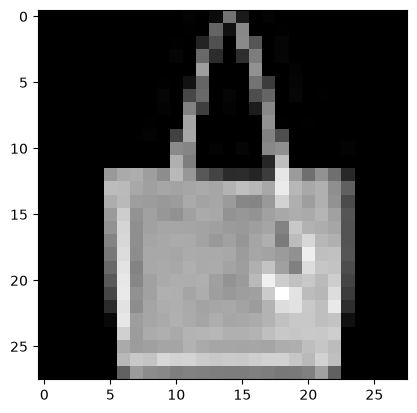

In [189]:
train_features, train_labels = next(iter(train_dataloader))
img = train_features[0].squeeze()
img
label = train_labels[0]
plt.imshow(img,cmap="grey")
plt.show()

In [190]:
from torch import nn

class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.Linear_relu_stack= nn.Sequential(
        nn.Flatten(),
        nn.Linear(28*28,512),
        nn.ReLU(),
        nn.Linear(512,512),
        nn.ReLU(),
        nn.Linear(512,10),
        )
    def forward(self,x):
        logits = self.Linear_relu_stack(x)
        return logits

In [191]:
device = (
        "mps" if torch.backends.mps.is_available()
        else "cuda"  if torch.cuda.is_available()
        else "cpu"
        )

In [192]:
model = NeuralNetwork().to(device)
model

NeuralNetwork(
  (Linear_relu_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=512, bias=True)
    (4): ReLU()
    (5): Linear(in_features=512, out_features=10, bias=True)
  )
)

In [193]:
learning_rate = 1e-3
batch_size = 64
epochs = 10

In [194]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(),lr=learning_rate)

In [195]:
optimizer2 = torch.optim.Adam(model.parameters(), lr=1e-3)

# forward prop

In [ ]:
def train_loop(dataloader,model,loss_fn,optimizer):
    model.train()
    
    for X,y in dataloader:
        X,y = X.to(device),y.to(device)
        
        logits = model(X) #calculate logits 
        loss = loss_fn(logits,y) #compute loss
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step() 

In [197]:
def test_loop(dataloader,model,loss_fn):
    model.eval()
    correct=0
    total_loss=0
    with torch.no_grad():
        for X,y in dataloader:
            X,y =X.to(device),y.to(device)
            
            logits = model(X)
            total_loss+=loss_fn(logits,y).item()
            correct+=(logits.argmax(1)==y).sum().item()
    accuracy= 100*correct/len(dataloader.dataset)
    average_loss = total_loss / len(dataloader)
    print(f"Test accuracy: {accuracy:.1f}% | Test loss: {average_loss:.4f}")

In [212]:

for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_dataloader, model, loss_fn, optimizer2)
    test_loop(test_dataloader, model, loss_fn)
print("Done!")

Epoch 1
-------------------------------
Test accuracy: 88.6% | Test loss: 0.3388
Epoch 2
-------------------------------
Test accuracy: 89.3% | Test loss: 0.3253
Epoch 3
-------------------------------
Test accuracy: 89.4% | Test loss: 0.3368
Epoch 4
-------------------------------
Test accuracy: 89.4% | Test loss: 0.3298
Epoch 5
-------------------------------
Test accuracy: 89.1% | Test loss: 0.3460
Epoch 6
-------------------------------
Test accuracy: 88.9% | Test loss: 0.3810
Epoch 7
-------------------------------
Test accuracy: 88.9% | Test loss: 0.3640
Epoch 8
-------------------------------
Test accuracy: 88.6% | Test loss: 0.3850
Epoch 9
-------------------------------
Test accuracy: 88.6% | Test loss: 0.3932
Epoch 10
-------------------------------
Test accuracy: 89.6% | Test loss: 0.3636
Done!


Predicted: T-shirt/top
Actual:    T-shirt/top


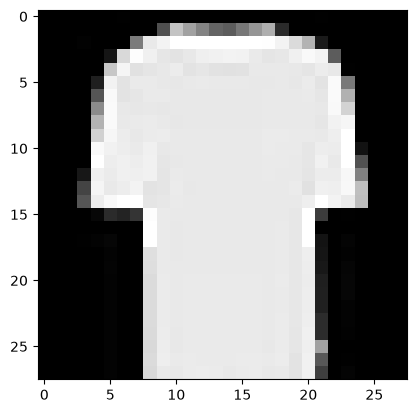

In [213]:
model.eval()

train_features, train_labels = next(iter(train_dataloader))

image , true_label= train_features[0].unsqueeze(0),train_labels[0]
image2=image.to(device)

with torch.no_grad():
    logits = model(image2)
    predict=logits.argmax(1).item()

print("Predicted:", test_data.classes[predict])
print("Actual:   ", test_data.classes[true_label])


img = image.squeeze()
img
label = train_labels[0]
plt.imshow(img,cmap="grey")
plt.show()



Predicted: Ankle boot
Actual:    Ankle boot


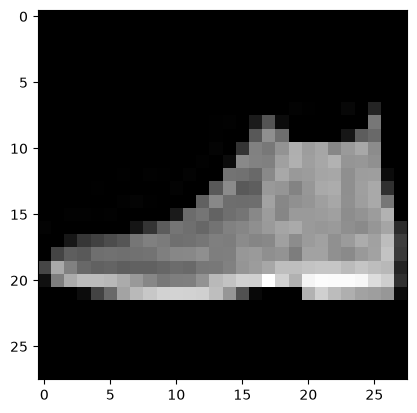

In [214]:
model.eval()

image, true_label = test_data[0]

with torch.no_grad():
    logits = model(image.unsqueeze(0).to(device))
    prediction = logits.argmax(dim=1).item()

print("Predicted:", test_data.classes[prediction])
print("Actual:   ", test_data.classes[true_label])

plt.imshow(image.squeeze(), cmap="gray")
plt.show()
